# Sales and student performance analysis

Name: Debottam Sarkar  
Registration number: 202400303

This notebook covers category-wise sales in Spark, multivariate analysis of real wine measurements, and subject-wise grade counts with a PCA view of student marks. Run the cells from top to bottom in a fresh Colab Python runtime.

Sales data is downloaded from Kaggle. The wine dataset ships with scikit-learn. The marks section starts with explicitly simulated data and accepts an approved results CSV when available.

In [1]:
%pip -q install pyspark==4.0.1 pandas==2.2.3 numpy==2.2.6 scikit-learn==1.6.1 matplotlib==3.10.0


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: /tmp/dwbda-notebooks-oSWVK5/test-env/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import os
import sys
import zipfile
from pathlib import Path
from tempfile import mkdtemp
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from pyspark.sql import SparkSession, functions as F

os.environ["PYSPARK_PYTHON"] = sys.executable
work = Path(mkdtemp(prefix="sales_analysis_"))
spark = (
    SparkSession.builder.master("local[2]")
    .appName("CategoryAndGradeAnalysis")
    .config("spark.sql.shuffle.partitions", "2")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/16 15:58:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark: 4.0.1


## 1. Quantity sold in each product category

The [Kaggle Sample Sales Data](https://www.kaggle.com/datasets/kyanyoga/sample-sales-data) contains order lines. Here, a completed sale means a row with status **Shipped**. Cancelled, disputed and unfinished orders are excluded; quantity is summed rather than counting rows.

If the automatic download is unavailable, upload `sales_data_sample.csv` into the Colab Files panel and rerun the next cell. The file is read as Latin-1 because some customer names contain accented characters.

In [3]:
csv_path = Path("sales_data_sample.csv")
if not csv_path.exists():
    url = "https://www.kaggle.com/api/v1/datasets/download/kyanyoga/sample-sales-data"
    try:
        request = Request(url)
        with urlopen(request, timeout=60) as response:
            payload = response.read()
        with zipfile.ZipFile(io.BytesIO(payload)) as archive:
            member = next(
                name for name in archive.namelist()
                if Path(name).name.lower() == "sales_data_sample.csv"
            )
            csv_path = work / "sales_data_sample.csv"
            csv_path.write_bytes(archive.read(member))
    except Exception as error:
        raise RuntimeError(
            "Upload sales_data_sample.csv from the linked Kaggle dataset, then rerun this cell."
        ) from error

orders = (
    spark.read.option("header", True)
    .option("encoding", "ISO-8859-1")
    .csv(str(csv_path))
)
required = {"PRODUCTLINE", "QUANTITYORDERED", "STATUS"}
if not required.issubset(orders.columns):
    raise ValueError(f"Expected columns: {sorted(required)}")
lines = orders.select(
    F.trim("PRODUCTLINE").alias("category"),
    F.expr("try_cast(QUANTITYORDERED as int)").alias("units"),
    F.upper(F.trim("STATUS")).alias("status")
)
completed = lines.where(F.col("status") == "SHIPPED")
invalid = completed.where(
    F.col("category").isNull() | (F.col("category") == "")
    | F.col("units").isNull() | (F.col("units") <= 0)
)
if invalid.count():
    raise ValueError("Completed orders contain an invalid category or quantity.")

category_sales = (
    completed.groupBy("category")
    .agg(F.sum("units").alias("products_sold"), F.count("*").alias("order_lines"))
    .orderBy(F.desc("products_sold"), "category")
)
sales_summary = category_sales.toPandas()
display(sales_summary)
assert int(sales_summary.products_sold.sum()) == completed.agg(F.sum("units")).first()[0]
sales_summary.to_csv(work / "category_sales.csv", index=False)
print(f"Counted {completed.count():,} completed order lines.")

,category,products_sold,order_lines
0,Classic Cars,31955,914
1,Vintage Cars,19281,557
2,Motorcycles,11355,324
3,Trucks and Buses,10009,281
4,Planes,9389,271
5,Ships,6792,195
6,Trains,2622,75


Counted 2,617 completed order lines.


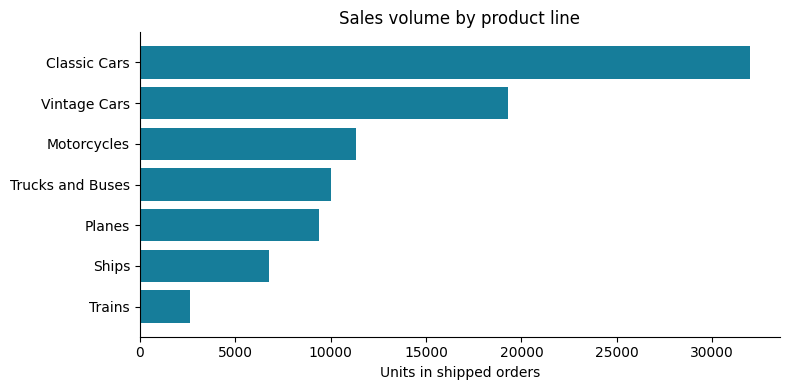

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_data = sales_summary.sort_values("products_sold")
ax.barh(plot_data.category, plot_data.products_sold, color="#167d9a")
ax.set(xlabel="Units in shipped orders", ylabel="", title="Sales volume by product line")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
plt.close(fig)

## 2. Multivariate analysis of wine measurements

The [UCI Wine dataset](https://archive.ics.uci.edu/dataset/109/wine), available through [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html), contains 178 real wine samples and 13 chemical measurements.

Measurements are standardized before PCA. The retained components explain at least 90% of the total variance. Ward hierarchical clustering is fitted to these components; the number of groups is selected from two to five using the silhouette score. Known cultivar labels are used only for a later comparison, not as clustering inputs.

In [5]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

wine_data = load_wine(as_frame=True)
measurements = wine_data.data
scaled_wine = StandardScaler().fit_transform(measurements)
projection = PCA(n_components=0.90, svd_solver="full")
wine_axes = projection.fit_transform(scaled_wine)

candidates = {}
for groups in range(2, 6):
    labels = AgglomerativeClustering(n_clusters=groups, linkage="ward").fit_predict(wine_axes)
    candidates[groups] = (silhouette_score(wine_axes, labels), labels)

chosen_groups = max(candidates, key=lambda groups: candidates[groups][0])
silhouette, membership = candidates[chosen_groups]
comparison = pd.DataFrame(
    [(groups, item[0]) for groups, item in candidates.items()],
    columns=["groups", "silhouette"]
)
display(comparison.round(4))
print(f"Samples: {len(measurements)}; measurements: {measurements.shape[1]}")
print(f"Retained components: {projection.n_components_}")
print(f"Variance retained: {projection.explained_variance_ratio_.sum():.1%}")
print(f"Selected groups: {chosen_groups}; silhouette: {silhouette:.3f}")

cluster_profile = measurements.assign(group=membership + 1).groupby("group").mean()
display(cluster_profile.round(2))
display(pd.crosstab(
    pd.Series(membership + 1, name="group"),
    pd.Series(wine_data.target.to_numpy() + 1, name="known_cultivar")
))

,groups,silhouette
0,2,0.2917
1,3,0.3047
2,4,0.3105
3,5,0.2534


Samples: 178; measurements: 13
Retained components: 8
Variance retained: 92.0%
Selected groups: 4; silhouette: 0.311


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
group,,,,,,,,,,,,,
1,12.20,1.98,2.23,20.39,89.44,2.27,2.10,0.36,1.62,2.89,1.05,2.87,485.05
2,13.06,3.17,2.41,21.00,99.86,1.69,0.85,0.45,1.13,6.85,0.72,1.73,624.95
3,12.55,1.72,2.55,22.16,135.57,2.59,2.68,0.34,2.30,3.73,1.13,3.05,774.29
4,13.73,1.96,2.43,16.95,104.90,2.84,2.99,0.28,1.91,5.53,1.07,3.15,1097.53


known_cultivar,1,2,3
group,,,
1,0,55,0
2,0,8,48
3,2,5,0
4,57,3,0


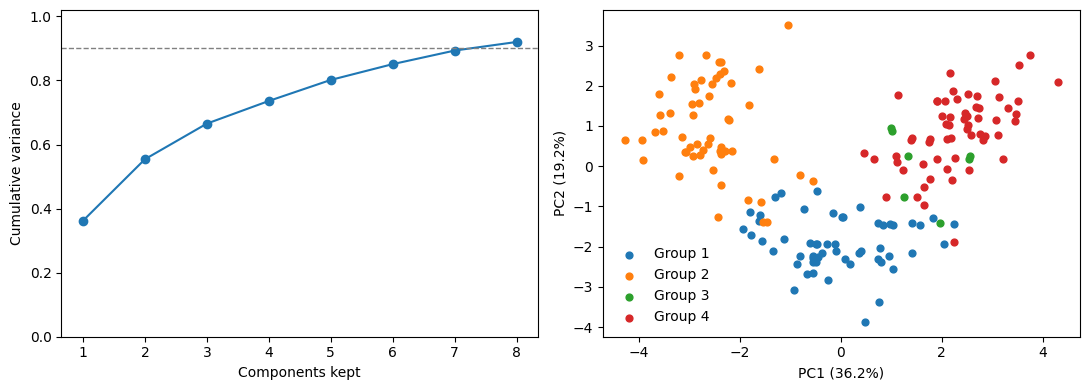

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
positions = np.arange(1, projection.n_components_ + 1)
axes[0].plot(positions, np.cumsum(projection.explained_variance_ratio_), marker="o")
axes[0].axhline(0.90, color="gray", linestyle="--", linewidth=1)
axes[0].set(xlabel="Components kept", ylabel="Cumulative variance", ylim=(0, 1.02))
for group in np.unique(membership):
    selected = membership == group
    axes[1].scatter(wine_axes[selected, 0], wine_axes[selected, 1], s=24, label=f"Group {group + 1}")
axes[1].set(
    xlabel=f"PC1 ({projection.explained_variance_ratio_[0]:.1%})",
    ylabel=f"PC2 ({projection.explained_variance_ratio_[1]:.1%})"
)
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()
plt.close(fig)

pd.DataFrame({
    "sample": np.arange(1, len(measurements) + 1),
    "group": membership + 1,
    "pc1": wine_axes[:, 0],
    "pc2": wine_axes[:, 1]
}).to_csv(work / "wine_groups.csv", index=False)

The silhouette score compares separation between groups with variation inside each group. It helps choose a grouping for this dataset but does not establish wine quality or commercial value. The two-dimensional chart shows only the first two axes; clustering uses all retained components.

## 3. Grade counts for every subject

Set `RESULTS_CSV` to an uploaded marks file to use actual previous-semester results. The first column must be `student_id`; every other column must contain a subject mark between 0 and 100. Blank input uses 24 generated student records for demonstration, not real semester results.

The assumed boundaries are S: 90–100, A: 80–<90, B: 70–<80, C: 60–<70, D: 50–<60, E: 40–<50, F: below 40. Change them if the course uses a different scheme. Overall grades use the unrounded mean.

In [7]:
RESULTS_CSV = ""

if RESULTS_CSV:
    marks = pd.read_csv(RESULTS_CSV)
    print("Loaded results from:", RESULTS_CSV)
else:
    generator = np.random.default_rng(271)
    ability = np.linspace(28, 96, 24)[:, None]
    values = np.clip(np.rint(ability + generator.normal(0, 9, (24, 5))), 0, 100)
    marks = pd.DataFrame(values, columns=["DBMS", "Networks", "Statistics", "Algorithms", "Python"])
    marks.insert(0, "student_id", [f"DEMO{i:02d}" for i in range(1, 25)])
    print("Using simulated marks for 24 students.")

if "student_id" not in marks or marks.student_id.isna().any() or marks.student_id.duplicated().any():
    raise ValueError("student_id must be present, unique and nonblank.")
subjects = marks.columns.drop("student_id").tolist()
if len(marks) < 2 or len(subjects) < 2:
    raise ValueError("At least two students and two subjects are needed.")
scores = marks[subjects].apply(pd.to_numeric, errors="raise")
if not np.isfinite(scores.to_numpy()).all() or not scores.ge(0).all().all() or not scores.le(100).all().all():
    raise ValueError("Every mark must be a finite number between 0 and 100.")
marks[subjects] = scores

grade_order = ["S", "A", "B", "C", "D", "E", "F"]
def grade_band(values):
    return pd.cut(
        values, bins=[0, 40, 50, 60, 70, 80, 90, 101],
        labels=["F", "E", "D", "C", "B", "A", "S"], right=False
    )

student_summary = marks[["student_id"]].copy()
student_summary["average"] = scores.mean(axis=1)
student_summary["grade"] = grade_band(student_summary["average"])
display(student_summary.round(2))

Using simulated marks for 24 students.


,student_id,average,grade
0,DEMO01,22.6,F
1,DEMO02,26.8,F
2,DEMO03,27.0,F
3,DEMO04,36.4,F
4,DEMO05,42.0,E
5,DEMO06,44.4,E
6,DEMO07,49.4,E
7,DEMO08,54.4,D
8,DEMO09,51.6,D
9,DEMO10,46.8,E


In [8]:
from operator import add

long_marks = marks.melt(id_vars="student_id", var_name="subject", value_name="mark")
long_marks["grade"] = grade_band(long_marks["mark"])
pairs = list(long_marks[["subject", "grade"]].itertuples(index=False, name=None))
counts = (
    spark.sparkContext.parallelize(pairs, 2)
    .map(lambda item: (item, 1))
    .reduceByKey(add)
    .collect()
)
count_rows = [(subject, grade, count) for (subject, grade), count in counts]
subject_counts = (
    pd.DataFrame(count_rows, columns=["subject", "grade", "students"])
    .pivot(index="subject", columns="grade", values="students")
    .reindex(index=subjects, columns=grade_order)
    .fillna(0).astype(int)
)
overall_counts = student_summary.grade.value_counts().reindex(grade_order, fill_value=0)
assert subject_counts.sum(axis=1).eq(len(marks)).all()
assert overall_counts.sum() == len(marks)
display(subject_counts)
display(overall_counts.rename("students").to_frame())
subject_counts.to_csv(work / "subject_grade_counts.csv")
student_summary.to_csv(work / "student_grades.csv", index=False)

grade,S,A,B,C,D,E,F
subject,,,,,,,
DBMS,2,2,6,3,3,4,4
Networks,6,4,0,4,3,3,4
Statistics,3,3,3,3,4,5,3
Algorithms,2,5,4,1,3,4,5
Python,3,2,6,1,6,2,4


,students
grade,
S,2
A,5
B,3
C,2
D,4
E,4
F,4


Each subject-grade pair is mapped to a count of one. Spark's `reduceByKey` adds the counts to produce the table above. PCA is a separate descriptive view of the marks and does not assign grades. Here it is calculated using a singular value decomposition of the standardized marks matrix.

The first two components retain 94.4% of mark variation.


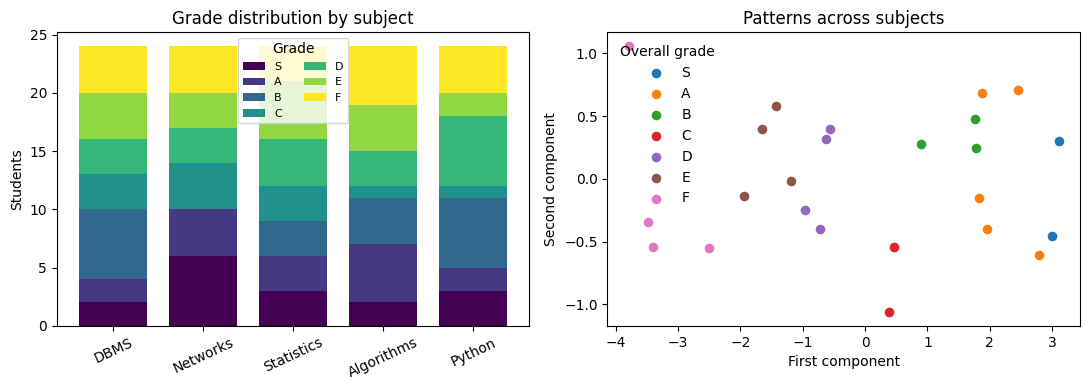

Result CSV files: category_sales.csv, sales_data_sample.csv, student_grades.csv, subject_grade_counts.csv, wine_groups.csv


In [9]:
mark_matrix = scores.to_numpy(dtype=float)
spread = mark_matrix.std(axis=0)
if np.count_nonzero(spread) < 2:
    raise ValueError("PCA needs at least two subjects with varying marks.")
normalized = (mark_matrix - mark_matrix.mean(axis=0)) / np.where(spread == 0, 1, spread)
left, singular_values, directions = np.linalg.svd(normalized, full_matrices=False)
student_axes = left[:, :2] * singular_values[:2]
variance_share = singular_values ** 2 / (singular_values ** 2).sum()
print(f"The first two components retain {variance_share[:2].sum():.1%} of mark variation.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
subject_counts.plot.bar(stacked=True, ax=axes[0], width=0.75, colormap="viridis")
axes[0].set(xlabel="", ylabel="Students", title="Grade distribution by subject")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(title="Grade", fontsize=8, ncol=2)
for grade in grade_order:
    selected = (student_summary.grade == grade).to_numpy()
    if selected.any():
        axes[1].scatter(student_axes[selected, 0], student_axes[selected, 1], label=grade, s=35)
axes[1].set(xlabel="First component", ylabel="Second component", title="Patterns across subjects")
axes[1].legend(title="Overall grade", frameon=False)
fig.tight_layout()
plt.show()
plt.close(fig)
spark.stop()
print("Result CSV files:", ", ".join(path.name for path in sorted(work.glob("*.csv"))))

## Interpretation

The sales table measures quantities from shipped order lines. The wine analysis groups samples by chemical similarity and reports how much information the PCA representation retains. The marks table counts every student once in each subject, while the PCA chart summarizes differences across subjects.